# Лабораторная работа №1. K ближайших соседей

Фокин Леонид Александрович, группа 401, вариант 20.

## Данные и метрики

**Wholesale Customers.** По структуре годовых закупок можно определить, обслуживает ли оптовик заведение Horeca или розничный магазин, например при переназначении клиентов между менеджерами. Цель `Channel`: 1 = Horeca, 2 = Retail. Классы неравны; macro-F1 даёт каждому одинаковый вес, accuracy оставляю для сравнения доли верных ответов.

**SGEMM GPU Kernel Performance.** Хочу оценить время матричного умножения для ещё не проверенных параметров одного GPU-ядра, чтобы сократить перебор замеров. Цель: среднее четырёх прогонов в мс. MAE даёт типичный масштаб абсолютной ошибки в тех же единицах, RMSE сильнее штрафует большие промахи. Случайный тест проверяет новые конфигурации из той же совокупности, а не перенос на другое железо.

Тест: 20%, `random_state=20`, для классификации со стратификацией. Во всех пяти работах используются одни и те же строки. CV и первые графики используют только обучающую часть. Источники и отбор строк: [data/README.md](data/README.md).

Загружаю общие функции разбиения и оценки. В этой работе библиотечный бейзлайн использует исходные числовые признаки.

In [1]:
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
import numpy as np
import pandas as pd
from IPython.display import display
from study import SEED, TASKS, evaluate, split, validate

BASE = 'raw'

def sklearn_model(task, params):
    if task == 'classification':
        return KNeighborsClassifier(**params)
    return KNeighborsRegressor(**params)

### Распределения в train

Проверяю дисбаланс классов и правый хвост времени выполнения. Логарифмическая шкала оси X не меняет целевую переменную модели.

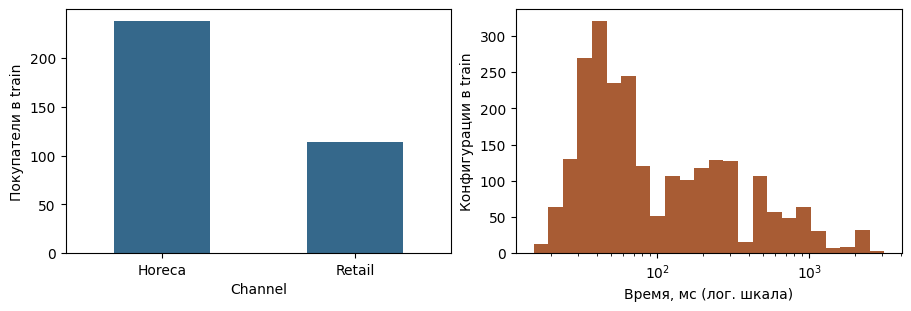

classification     352
regression        2400
Name: train, dtype: int64

In [2]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor

_, _, labels, _ = split('classification')
_, _, runtimes, _ = split('regression')
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3), layout='constrained')
labels.value_counts().rename(index={1: 'Horeca', 2: 'Retail'}).plot.bar(ax=a, rot=0, color='#35688b')
a.set(ylabel='Покупатели в train')
b.hist(runtimes, bins=np.geomspace(runtimes.min(), runtimes.max(), 25), color='#a85c34')
b.set(xscale='log', xlabel='Время, мс (лог. шкала)', ylabel='Конфигурации в train')
plt.show()
display(pd.Series({task: len(split(task)[0]) for task in TASKS}, name='train'))

В качестве нижней точки отсчёта: самый частый канал и медианное время. Эти модели не участвуют в подборе параметров.

In [3]:
dummy = [evaluate('classification', DummyClassifier(strategy='most_frequent'))[0],
         evaluate('regression', DummyRegressor(strategy='median'))[0]]
display(pd.DataFrame(dummy).drop(columns='fit_seconds').round(4))

,task,f1_macro,accuracy,mae_ms,rmse_ms
0,classification,0.4054,0.6818,NaN,NaN
1,regression,NaN,NaN,157.9974,359.0561


## Бейзлайн sklearn

Фиксирую качество моделей со стандартными параметрами. Тестовые оценки не участвуют в выборе конфигурации.

In [4]:
baseline = {task: evaluate(task, sklearn_model(task, {}), BASE) for task in TASKS}
display(pd.DataFrame([metrics for metrics, _ in baseline.values()]).round(4))

,task,f1_macro,accuracy,fit_seconds,mae_ms,rmse_ms
0,classification,0.862,0.875,0.0010,NaN,NaN
1,regression,NaN,NaN,0.0023,88.9032,205.3894


## Гипотезы и кросс-валидация

Суммы расходов и размеры плиток имеют разные масштабы. Проверяю стандартизацию отдельно от новых признаков. Для покупателей новые признаки выделяют доли категорий и заменяют код региона индикаторами; для SGEMM описывают геометрию плитки и потока. Меняю число соседей, норму и веса: большее k сглаживает предсказание, а веса по расстоянию уменьшают влияние дальних точек.

В обоих случаях 5 фолдов. Сравниваю препроцессинг без подбора, подбор без изменения признаков и их комбинацию. Сначала выбираю лучшую альтернативу бейзлайну на CV, затем оцениваю её на отложенной части. `cv_std` показывает разброс оценок по фолдам, это не доверительный интервал.

In [5]:
feature_options = ['scale', 'features_scale']
class_grid = [{'n_neighbors': 3, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 3, 'weights': 'distance', 'p': 1}, {'n_neighbors': 3, 'weights': 'distance', 'p': 2}, {'n_neighbors': 9, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 9, 'weights': 'distance', 'p': 1}, {'n_neighbors': 9, 'weights': 'distance', 'p': 2}, {'n_neighbors': 21, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 21, 'weights': 'distance', 'p': 1}, {'n_neighbors': 21, 'weights': 'distance', 'p': 2}]
reg_grid = [{'n_neighbors': 3, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 3, 'weights': 'distance', 'p': 1}, {'n_neighbors': 3, 'weights': 'distance', 'p': 2}, {'n_neighbors': 9, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 9, 'weights': 'distance', 'p': 1}, {'n_neighbors': 9, 'weights': 'distance', 'p': 2}, {'n_neighbors': 21, 'weights': 'uniform', 'p': 2}, {'n_neighbors': 21, 'weights': 'distance', 'p': 1}, {'n_neighbors': 21, 'weights': 'distance', 'p': 2}]
tables, chosen = {}, {}
for task, grid in zip(TASKS, (class_grid, reg_grid)):
    candidates = [('baseline', BASE, {})]
    candidates += [('preprocessing', prep, {}) for prep in feature_options]
    candidates += [('parameters', BASE, params) for params in grid]
    candidates += [('combined', prep, params) for prep in feature_options for params in grid]
    table = tables[task] = validate(task, lambda params: sklearn_model(task, params), candidates)
    chosen[task] = table.loc[table.experiment != 'baseline'].iloc[0]
    print(task)
    display(table.drop_duplicates('experiment').round(4).reset_index(drop=True))

classification


,experiment,prep,params,cv_mean,cv_std
0,parameters,raw,"{'n_neighbors': 9, 'weights': 'distance', 'p': 1}",0.9026,0.0145
1,combined,scale,"{'n_neighbors': 9, 'weights': 'distance', 'p': 2}",0.9023,0.0223
2,preprocessing,scale,{},0.8886,0.0286
3,baseline,raw,{},0.8832,0.0119


regression


,experiment,prep,params,cv_mean,cv_std
0,combined,features_scale,"{'n_neighbors': 3, 'weights': 'distance', 'p': 1}",69.6306,6.4648
1,parameters,raw,"{'n_neighbors': 3, 'weights': 'distance', 'p': 1}",83.2790,5.9729
2,baseline,raw,{},92.6739,5.2472
3,preprocessing,features_scale,{},94.8314,11.1350


Лучший вариант из альтернатив заново обучаю на всём train. Прирост на CV не гарантирует прироста на тесте.

In [6]:
improved = {task: evaluate(task, sklearn_model(task, row.params), row.prep)
            for task, row in chosen.items()}
display(pd.DataFrame([metrics for metrics, _ in improved.values()]).round(4))

,task,f1_macro,accuracy,fit_seconds,mae_ms,rmse_ms
0,classification,0.8989,0.9091,0.0011,NaN,NaN
1,regression,NaN,NaN,0.0036,56.7358,112.5752


## Самописная реализация

Реализация напрямую считает расстояния Минковского. Регрессия усредняет цели соседей, классификация суммирует веса по классам. При нулевых расстояниях в режиме `distance` учитываются только точные совпадения. При равенстве голосов выбирается меньшая метка; при равных расстояниях самописная модель сохраняет порядок обучающей выборки.

Самописный алгоритм проверяется с обоими рецептами sklearn: исходным и выбранным по CV. Приёмы обработки признаков общие, чтобы сравнить реализацию модели, а не разные входные данные.

In [7]:
from models.knn import KNN

def own_model(task, params):
    return KNN(task, **params)

own_base = {task: evaluate(task, own_model(task, {}), BASE) for task in TASKS}
own_improved = {task: evaluate(task, own_model(task, row.params), row.prep)
                for task, row in chosen.items()}

Сохраняю четыре сравнимые строки на задачу. `Δ` ниже означает разницу с соответствующим библиотечным или исходным вариантом, а не процентное изменение. Для MAE отрицательная разница означает улучшение.

In [8]:
versions = {'sklearn baseline': baseline, 'sklearn improved': improved,
            'own baseline': own_base, 'own improved': own_improved}
scores = pd.DataFrame([dict(version=version, **metrics)
                       for version, outcomes in versions.items()
                       for metrics, _ in outcomes.values()])
from pathlib import Path

Path('results').mkdir(exist_ok=True)
scores.drop(columns='fit_seconds').to_csv('results/lab1.csv', index=False)
for task, metric in zip(TASKS, ('f1_macro', 'mae_ms')):
    subset = scores.query('task == @task').dropna(axis=1).set_index('version')
    display(subset.drop(columns='task').round(4))
    s = subset[metric]
    display(pd.Series({'sklearn improved − sklearn baseline': s.iloc[1] - s.iloc[0],
                       'own baseline − sklearn baseline': s.iloc[2] - s.iloc[0],
                       'own improved − sklearn improved': s.iloc[3] - s.iloc[1],
                       'own improved − own baseline': s.iloc[3] - s.iloc[2]},
                      name=f'Δ {metric}').round(4))

,f1_macro,accuracy,fit_seconds
version,,,
sklearn baseline,0.8620,0.8750,0.0010
sklearn improved,0.8989,0.9091,0.0011
own baseline,0.8620,0.8750,0.0003
own improved,0.8989,0.9091,0.0002


sklearn improved − sklearn baseline    0.0368
own baseline − sklearn baseline        0.0000
own improved − sklearn improved        0.0000
own improved − own baseline            0.0368
Name: Δ f1_macro, dtype: float64

,fit_seconds,mae_ms,rmse_ms
version,,,
sklearn baseline,0.0023,88.9032,205.3894
sklearn improved,0.0036,56.7358,112.5752
own baseline,0.0002,89.0911,205.3993
own improved,0.0032,56.7358,112.5752


sklearn improved − sklearn baseline   -32.1674
own baseline − sklearn baseline         0.1879
own improved − sklearn improved         0.0000
own improved − own baseline           -32.3552
Name: Δ mae_ms, dtype: float64

Сравниваю ошибки обеих улучшенных моделей на тех же тестовых объектах. Матрица показывает, какие классы путаются. В регрессии сравниваю величину ошибки на быстрых и медленных конфигурациях; медианный порог беру из train.

In [9]:
from sklearn.metrics import confusion_matrix

_, _, _, test_channel = split('classification')
_, _, train_time, test_time = split('regression')
bands = np.where(test_time <= train_time.median(), 'быстрые', 'медленные')
for label, outcomes in [('sklearn', improved), ('самописная', own_improved)]:
    print(label)
    display(pd.DataFrame(confusion_matrix(test_channel, outcomes['classification'][1], labels=[1, 2]),
                         index=['факт Horeca', 'факт Retail'],
                         columns=['прогноз Horeca', 'прогноз Retail']))
    error = np.abs(np.asarray(test_time) - outcomes['regression'][1])
    display(pd.Series(error).groupby(bands).agg(['size', 'mean']).round(2))

sklearn


,прогноз Horeca,прогноз Retail
факт Horeca,54,6
факт Retail,2,26


,size,mean
быстрые,308,23.41
медленные,292,91.89


самописная


,прогноз Horeca,прогноз Retail
факт Horeca,54,6
факт Retail,2,26


,size,mean
быстрые,308,23.41
медленные,292,91.89


## Выводы

- **Классификация.** На CV исходный macro-F1 0,8832, лучшая альтернатива 0,9026: девять соседей, манхэттенское расстояние и веса по расстоянию, без масштабирования. Масштабирование само по себе помогло, но лучший совместный рецепт дал 0,9023, слишком близко, чтобы считать преимущество устойчивым. На тесте macro-F1 вырос с 0,8620 до 0,8989; обе реализации дали одинаковые итоговые оценки.
- **Регрессия.** Настройка по исходным признакам снизила CV MAE с 92,67 до 83,28 мс; три взвешенных соседа вместе с новыми признаками и масштабированием снизили её до 69,63 мс. Препроцессинг со стандартным KNN такого эффекта не дал. На тесте MAE снизилась с 88,90 до 56,74 мс. Самописный бейзлайн получил 89,09 мс: при дискретных параметрах GPU встречаются равные расстояния, и реализация может выбрать других соседей на границе top-k. Улучшенные варианты совпали по MAE и RMSE.